# Two-Channel Chew-Mandelstam Formalism [Stable]
___

In [54]:
from __future__ import annotations
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, differential_evolution, least_squares, root


# =============================================================================
# Data and masses (GeV)
# =============================================================================
DATA_PATH = Path(r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv")

m_D0 = 1.86484
m_Dstar_plus = 2.01026
m_pi_plus = 0.13957

# Channel 1: D0 + (D0 pi+) isobar; channel 2: D0 + D*+.
M1, m1 = m_D0 + m_pi_plus, m_D0
M2, m2 = m_Dstar_plus, m_D0

STH1 = (M1 + m1) ** 2
SDIFF1 = (M1 - m1) ** 2
STH2 = (M2 + m2) ** 2
SDIFF2 = (M2 - m2) ** 2
WTH1 = M1 + m1
WTH2 = M2 + m2

# Only selects the upper rim for exactly real values of s. This is not a
# detector-resolution parameter or a fit parameter.
REAL_AXIS_EPS = 1.0e-14

# Branch-selection width for the lambda=0 near-threshold virtual state.
# This selects the near-threshold trajectory branch, not a fitted K22 value.
VIRTUAL_POLE_WINDOW_MEV = 0.25

# Fixed Gauss-Legendre quadrature order for averaging over the CSV bins.
BIN_QUADRATURE_ORDER = 24

The function also extracts the lower and upper edges of each experimental mass bin, $W_i^{\mathrm{low}}, \quad W_i^{\mathrm{high}}.$ These are subsequently used for numerical bin integration. The validity condition requires $\sigma_i>0,$ and all relevant quantities must be finite. Thus the data entering the fit are
$$\left\{ W_i, Y_i, \sigma_i, W_i^{\mathrm{low}}, W_i^{\mathrm{high}} \right\}.$$

In [55]:
def load_lhcb_data(path: Path):
    """Load the requested columns, plus bin edges for bin-averaged fitting."""
    df_data = pd.read_csv(path, comment="#")

    # These three columns follow the exact indexing specified in the request.
    data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
    data_yield = df_data.iloc[:, 3].values
    data_err = np.abs(df_data.iloc[:, 4].values)

    # The file also supplies lower/upper mass-bin edges (columns 1 and 2).
    data_bin_low_GeV = df_data.iloc[:, 1].values
    data_bin_high_GeV = df_data.iloc[:, 2].values
    data_mass_GeV = data_mass_MeV / 1000.0

    valid = (
        np.isfinite(data_mass_MeV)
        & np.isfinite(data_yield)
        & np.isfinite(data_err)
        & np.isfinite(data_bin_low_GeV)
        & np.isfinite(data_bin_high_GeV)
        & (data_err > 0.0)
        & (data_bin_high_GeV > data_bin_low_GeV)
    )
    return (
        df_data.loc[valid].reset_index(drop=True),
        data_mass_MeV[valid],
        data_mass_GeV[valid],
        data_bin_low_GeV[valid],
        data_bin_high_GeV[valid],
        data_yield[valid],
        data_err[valid],
    )

___
The function `make_bin_quadrature()` constructs **Gauss--Legendre** integration points inside every experimental mass bin. The purpose is to calculate the bin-averaged theoretical prediction
$$\frac{1}{W_i^{\mathrm{high}}-W_i^{\mathrm{low}}} \int_{W_i^{\mathrm{low}}}^{W_i^{\mathrm{high}}} Y(W)\,dW.$$
This is important near a threshold because the theoretical line shape can
vary rapidly over a single experimental bin. The Gauss--Legendre nodes $x_j$ satisfy $-1\leq x_j\leq1,$ and the corresponding physical energy is
$$\frac{W_i^{\mathrm{high}}+W_i^{\mathrm{low}}}{2} + \frac{W_i^{\mathrm{high}}-W_i^{\mathrm{low}}}{2}x_j.$$
Therefore,
$$\overline{Y}_i \simeq \frac{1}{2} \sum_j w_j Y(W_{ij}),$$
where $w_j$ are the Gauss--Legendre weights. The factor of $1/2$ arises because the normalization by the bin width cancels the Jacobian
$$dW = \frac{W_i^{\mathrm{high}}-W_i^{\mathrm{low}}}{2}\,dx.$$
This procedure is \emph{not} experimental-resolution smearing. No Gaussian resolution function of the form
$$\frac{1}{\sqrt{2\pi}\sigma} \exp\left[ -\frac{(W-W')^2}{2\sigma^2} \right]$$
is introduced.

In [56]:
def make_bin_quadrature(bin_low_GeV, bin_high_GeV, order=BIN_QUADRATURE_ORDER):
    """
    Return Gauss-Legendre nodes and weights for each bin's *average* yield.
    With E=sqrt(s), Eq. (6) without the resolution function is the average of
    N p1 |F1|^2 over E in each bin. The weights below sum to one per bin.
    """
    nodes, weights = np.polynomial.legendre.leggauss(order)
    midpoint = 0.5 * (bin_low_GeV + bin_high_GeV)
    half_width = 0.5 * (bin_high_GeV - bin_low_GeV)
    W_quadrature = midpoint[:, None] + half_width[:, None] * nodes[None, :]
    average_weights = 0.5 * weights
    return W_quadrature, average_weights

___
The function `_select_upper_rim()` handles the physical boundary value of the Chew--Mandelstam function on the real axis. For an exactly real value of $s$, the code replaces $s$ by $s+i\epsilon,$ with $\epsilon=10^{-14}.$ Thus, $s\rightarrow s+i0^+. This specifies the upper rim of the physical branch cut. The infinitesimal imaginary displacement is numerical rather than physical. It is not a fitted width and does not represent experimental resolution.

In [57]:
def _select_upper_rim(s):
    """For exactly real s, select the physical upper edge of the cut."""
    s = np.asarray(s, dtype=complex)
    on_real_axis = np.abs(s.imag) == 0.0
    if np.any(on_real_axis):
        s = s.copy()
        s[on_real_axis] += 1j * REAL_AXIS_EPS
    return s

___
For $s>s_{\mathrm{th}},$ the physical upper-rim value has $\operatorname{Im}C(s+i0^+)>0$ under the convention used by the code. The analytic structure of $C(s)$ is essential because the scattering poles are not ordinary real-axis resonances. They are zeros of the analytic continuation of the scattering denominator on different Riemann sheets.

In [58]:
def chew_mandelstam(s, M, m):
    """
    Analytic Chew-Mandelstam function C(s; M,m), with Im C= rho above cut.

    This is the closed-form CM function used in the paper. For complex s it is
    evaluated as-is; exactly real inputs are moved infinitesimally to the upper
    rim to avoid an ambiguous principal-log value on the cut.
    """
    s = _select_upper_rim(s)
    sth = (M + m) ** 2
    sdiff = (M - m) ** 2

    rho = np.sqrt((s - sth) * (s - sdiff)) / s
    root_th = np.sqrt(sth - s)
    root_diff = np.sqrt(sdiff - s)
    ratio = (root_th - root_diff) / (root_th + root_diff)

    coefficient = (
        (M**2 - m**2) / (np.pi * s)
        - (M**2 + m**2) / (np.pi * (M**2 - m**2))
    )
    constant = coefficient * np.log(m / M) + 1.0 / np.pi
    return constant + (rho / np.pi) * np.log(ratio)

___
The function `rho_for_sheet_change()` constructs the discontinuity of the Chew--Mandelstam function across its unitarity cut. It evaluates
$$\frac{i\sqrt{s_{\mathrm{th}}-s}\sqrt{s-s_{\mathrm{diff}}}}{s}.$$
The continuation from one sheet to another is implemented through
$$C_{\mathrm{bottom}}(s) = C_{\mathrm{top}}(s)-2i\rho(s).$$
This relation follows from the discontinuity across the two branch cut.

In [59]:
def rho_for_sheet_change(s, M, m):
    """Rho branch used to continue C across the right-hand cut."""
    s = _select_upper_rim(s)
    sth = (M + m) ** 2
    sdiff = (M - m) ** 2
    return 1j * np.sqrt(sth - s) * np.sqrt(s - sdiff) / s

___
The function `cm_on_sheet(s,M,m,sheet_letter)` selects either the top or bottom Riemann sheet. For the top sheet,
$$C_t(s)=C(s).$$
For the bottom sheet,
$$C_b(s) = C(s)-2i\rho(s).$$
The labels used by the code are
$$t=\text{top sheet}, \qquad b=\text{bottom sheet}.$$
Therefore a two-channel sheet is specified by two letters, $[\sigma_1\sigma_2],$ where the first letter refers to channel 1 and the second letter refers to channel 2.

In [60]:
def cm_on_sheet(s, M, m, sheet_letter):
    """Use 't' for the physical/top sheet and 'b' for the cut-flipped sheet."""
    c_physical = chew_mandelstam(s, M, m)
    if sheet_letter == "t":
        return c_physical
    if sheet_letter == "b":
        return c_physical - 2j * rho_for_sheet_change(s, M, m)
    raise ValueError("Each sheet character must be 't' or 'b'.")

___
The function `cm_pair(W,sheet)` calculates the two channel Chew--Mandelstam functions, $C_1(W), \quad C_2(W),$ for a specified Riemann sheet. The function first converts the complex center-of-mass energy into the Mandelstam variable $s$. For example, on the $[bt]$ sheet,
$$C_1=C_{1,b}, \qquad C_2=C_{2,t}.$$

In [61]:
def cm_pair(W, sheet="tt"):
    """Return (C1,C2) for complex total energy W and sheet label, e.g. 'bt'."""
    s = np.asarray(W, dtype=complex) ** 2
    return (
        cm_on_sheet(s, M1, m1, sheet[0]),
        cm_on_sheet(s, M2, m2, sheet[1]),
    )

___
The function `phase_space_p1(W)` calculates the channel-1 center-of-mass momentum. For two particles of masses $M_1$ and $m_1$,
$$p_1(W) = \frac{\sqrt{[W^2-(M_1+m_1)^2][W^2-(M_1-m_1)^2]}}{2W}.$$
Equivalently, using the Källén function,
$$\lambda(x,y,z) = x^2+y^2+z^2-2xy-2xz-2yz,$$
one may write
$$p_1(W) = \frac{\sqrt{\lambda(W^2,M_1^2,m_1^2)}}{2W}.$$
For the real physical line shape below threshold, the momentum is set to zero because the physical phase space is closed:
$$p_1(W)=0, \qquad W<W_{\mathrm{th},1}.p_1(W)=0, \qquad W<W_{\mathrm{th},1}.$$

In [62]:
def phase_space_p1(W):
    """Channel-1 momentum p1 = sqrt(lambda(s,M1^2,m1^2))/(2 sqrt(s))."""
    W = np.asarray(W, dtype=float)
    s = W**2
    radicand = (s - STH1) * (s - SDIFF1)
    return np.sqrt(np.maximum(radicand, 0.0)) / (2.0 * W)

___
Yield Function `line_shape(...)`: 

In [63]:
def line_shape(W, K11, K12, K22, alpha2, log10_norm):
    W = np.asarray(W, dtype=float)
    C1, C2 = cm_pair(W, sheet="tt")
    det = (1.0 - K11 * C1) * (1.0 - K22 * C2) - (K12**2) * C1 * C2

    T11 = (K11 * (1.0 - K22 * C2) + (K12**2) * C2) / det
    T12 = K12 / det
    F1 = T11 + alpha2 * T12
    normalization = 10.0**log10_norm
    return normalization * phase_space_p1(W) * np.abs(F1) ** 2

___
The function `bin_averaged_line_shape()` evaluates the theoretical prediction at the Gauss--Legendre points and averages it over every experimental mass bin.
For the $i$-th bin,
$$Y_i^{\mathrm{th}} = \frac{1}{\Delta W_i} \int_{W_i^{\mathrm{low}}}^{W_i^{\mathrm{high}}} Y(W)\,dW.$$
Numerically,
$$Y_i^{\mathrm{th}} \simeq \frac{1}{2} \sum_j w_j Y(W_{ij}).$$
This is the quantity compared with the experimental value $Y_i$.

In [64]:
def bin_averaged_line_shape(params, W_quadrature, average_weights):
    """Model prediction averaged over the recorded mass bin of each point."""
    values_at_nodes = line_shape(W_quadrature, *params)
    return np.sum(values_at_nodes * average_weights[None, :], axis=1)

___
The function `residuals_for_fit()` constructs the normalized residuals used by the least-squares optimizer. For each data point,
$$r_i = \frac{Y_i^{\mathrm{th}}-Y_i^{\mathrm{exp}}}{\sigma_i}.$$
The total chi-squared is
$$\chi^2 = \sum_i r_i^2 = \sum_i \frac{\left( Y_i^{\mathrm{th}}-Y_i^{\mathrm{exp}} \right)^2}{\sigma_i^2}.$$
The objective function is therefore the standard weighted least-squares function.

In [65]:
def residuals_for_fit(params, W_quadrature, average_weights, y_data, y_err):
    prediction = bin_averaged_line_shape(params, W_quadrature, average_weights)
    if not np.all(np.isfinite(prediction)):
        return np.full_like(y_data, 1.0e12, dtype=float)
    return (prediction - y_data) / y_err

___
_**Different parameter sets can produce similar line shapes but different pole configurations**_ . To select the near-threshold virtual-state branch, the code derives an allowed interval for $K_{22}$. When $\lambda=0,$ the off-diagonal coupling vanishes, $K_{12}\rightarrow0.$ The channel-2 pole condition then becomes
$$1-K_{22}C_{2,b}(W)=0 \quad \implies \quad K_{22} = \frac{1}{C_{2,b}(W)}.$$
The code evaluates this quantity for an energy interval around the lower threshold and obtains a corresponding allowed interval for $K_{22}$. For the calculation presented here, the branch-selection window is
$$\left| W_{\mathrm{pole}}-W_{\mathrm{th},1} \right| < 0.25~\mathrm{MeV}.$$
It specifies which near-threshold solution branch is being investigated.

In [66]:
def derive_K22_bounds_for_virtual_branch(window_MeV=VIRTUAL_POLE_WINDOW_MEV):
    """Derive K22 bounds that put the uncoupled [tb] pole near channel-1 threshold.
    """
    half_window_GeV = window_MeV / 1000.0
    W_low = WTH1 - half_window_GeV
    W_high = WTH1 + half_window_GeV

    def C2_b_real(W):
        s = complex(W**2, REAL_AXIS_EPS)
        return float(np.real(cm_on_sheet(s, M2, m2, "b")))

    c_low = C2_b_real(W_low)
    c_high = C2_b_real(W_high)
    k_low = 1.0 / max(c_low, 1.0e-12)
    k_high = 1.0 / max(c_high, 1.0e-12)
    if k_low > k_high:
        k_low, k_high = k_high, k_low
    margin = min(1.0e-5, 0.05 * (k_high - k_low))
    return k_low + margin, k_high - margin

___
`fit_without_manual_initial_guess()` is the main fitting function. The parameter vector is
$$\bm{\theta} = (K_{11},K_{12},K_{22},\alpha_2,\log_{10}N).$$
The fitting procedure has two stages. The code minimizes
$$\chi^2(\bm{\theta}) = \sum_i \left[ \frac{Y_i^{\mathrm{th}}(\bm{\theta})-Y_i^{\mathrm{exp}}}{\sigma_i} \right]^2.$$
Differential evolution is a population-based global optimization algorithm. It therefore does not require a manually selected initial parameter vector.
The search takes place inside broad parameter ranges such as
$$-1<K_{11}<1,$$
$$0.1<K_{12}<1.5,$$
$$-2<\alpha_2<2,$$
$$-1<\log_{10}N<5.$$
The $K_{22}$ range is obtained automatically from the near-threshold virtual-state condition described above. The optimizer generates a population of candidate parameter vectors and iteratively evolves them toward smaller values of $\chi^2$.

The best parameter vector found by differential evolution is then supplied
automatically to `scipy.optimize.least_squares` for local refinement [no initial values]. It is generated by the global search. Thus the workflow is
$$\boxed{
\text{parameter search}
\longrightarrow
\text{automatic candidate}
\longrightarrow
\text{least-squares refinement}
}.$$

In [67]:
def fit_without_manual_initial_guess(W_quadrature, average_weights, y_data, y_err):
    """Global search followed by least-squares polishing; no manual start vector."""
    k22_low, k22_high = derive_K22_bounds_for_virtual_branch()

    # Broad effective-range search domains. K12 is taken positive because a
    # channel phase redefinition can reverse its sign while changing alpha2.
    # K22's interval is derived from the virtual-state branch condition above.
    bounds = [
        (-1.0, 1.0),          # K11
        (0.01, 1.5),           # K12
        (k22_low, k22_high),  # K22 (derived, not fixed)
        (-2.0, 2.0),          # alpha2
        (-1.0, 5.0),          # log10(N), so N is positive
    ]

    def chi2_objective(params):
        r = residuals_for_fit(
            params, W_quadrature, average_weights, y_data, y_err
        )
        return float(r @ r) if np.all(np.isfinite(r)) else 1.0e100

    print("Running global least-squares search; no manual fit vector is supplied...")
    global_result = differential_evolution(
        chi2_objective,
        bounds=bounds,
        strategy="best1bin",
        maxiter=650,
        popsize=14,
        tol=2.0e-5,
        mutation=(0.5, 1.0),
        recombination=0.7,
        init="latinhypercube",
        polish=False,
        seed=20261010,
        updating="immediate",
        workers=1,
        disp=False,
    )
    # The only local starting vector is produced by the global search itself.
    lower = np.array([pair[0] for pair in bounds], dtype=float)
    upper = np.array([pair[1] for pair in bounds], dtype=float)
    least_squares_result = least_squares(
        residuals_for_fit,
        x0=global_result.x,
        args=(W_quadrature, average_weights, y_data, y_err),
        bounds=(lower, upper),
        method="trf",
        x_scale="jac",
        ftol=1.0e-12,
        xtol=1.0e-12,
        gtol=1.0e-12,
        max_nfev=8000,
        verbose=0,
    )
    params = least_squares_result.x
    final_residuals = residuals_for_fit(
        params, W_quadrature, average_weights, y_data, y_err
    )
    chi2 = float(final_residuals @ final_residuals)
    dof = len(y_data) - len(params)
    return params, chi2, dof, bounds, global_result, least_squares_result

___
The function `determinant_denominator()` evaluates
$$D(W;\lambda) = (1-K_{11}C_1)(1-K_{22}C_2) - (\lambda K_{12})^2C_1C_2.$$
The introduction of $\lambda$ is important for the pole trajectory. The off-diagonal coupling is continuously modified according to $K_{12}(\lambda)=\lambda K_{12}.$ Therefore,
$$D(W;\lambda) = (1-K_{11}C_1)(1-K_{22}C_2) - \lambda^2K_{12}^2C_1C_2.$$
At $\lambda=1,$ the physical coupled-channel model is recovered. At $\lambda=0,$ the two channels decouple.

In [68]:
def determinant_denominator(W, K11, K12, K22, lam=1.0, sheet="tt"):
    """D(W)=det(I-KC); its zeros are the poles of T."""
    C1, C2 = cm_pair(W, sheet=sheet)
    k12 = lam * K12
    return (1.0 - K11 * C1) * (1.0 - K22 * C2) - (k12**2) * C1 * C2

___
The function `_newton_roots_from_power_sums()` takes the power sums
$$A_k=\sum_j z_j^k$$
where $z_j$ are the roots and reconstructs these roots using Newton's identities. Let $e_k$ denote the elementary symmetric polynomials of the roots.
Newton's identities give
$$m e_m = \sum_{k=1}^{m} (-1)^{k-1}e_{m-k}A_k,$$
with $e_0=1.$ Once the $e_k$ are known, the polynomial whose roots are the enclosed zeros is
$$P(z) = z^n - e_1z^{n-1} + e_2z^{n-2} - \cdots + (-1)^ne_n.$$
The numerical roots of this polynomial provide approximations to the
zeros of the original function.

In [69]:
def _newton_roots_from_power_sums(power_sums, number_of_roots):
    """Recover roots from Delves-Lyness power sums using Newton identities."""
    if number_of_roots == 1:
        return np.array([power_sums[1]], dtype=complex)

    elementary = np.zeros(number_of_roots + 1, dtype=complex)
    elementary[0] = 1.0
    for m in range(1, number_of_roots + 1):
        total = 0.0j
        for k in range(1, m + 1):
            total += ((-1) ** (k - 1)) * elementary[m - k] * power_sums[k]
        elementary[m] = total / m

    # Monic polynomial: z^n - e1*z^(n-1) + e2*z^(n-2) - ... + (-1)^n*en.
    coefficients = np.array(
        [((-1) ** k) * elementary[k] for k in range(number_of_roots + 1)],
        dtype=complex,
    )
    return np.roots(coefficients)

___
The function `delves_lyness_roots()` finds zeros of a complex analytic function inside a contour. Instead of starting with an arbitrary initial guess for the pole, the Delves--Lyness method determines the number and approximate positions of zeros enclosed by a contour. For a function $f(z)$, the logarithmic derivative is
$$\frac{f'(z)}{f(z)}.$$
Using the argument principle,
$$\frac{1}{2\pi i} \oint_{\Gamma} \frac{f'(z)}{f(z)}\,dz$$
counts the number of zeros minus the number of poles inside the contour. If $f$ has no poles inside $\Gamma$, this gives the number of zeros,
$$N_{\mathrm{zeros}} = \frac{1}{2\pi i} \oint_{\Gamma} \frac{f'(z)}{f(z)}\,dz.$$
The higher moments are
$$A_k = \frac{1}{2\pi i} \oint_{\Gamma} z^k \frac{f'(z)}{f(z)}\,dz.$$
If the zeros are $z_1,\ldots,z_n$, then
$$A_k = \sum_{j=1}^{n}z_j^k.$$
Thus, $A_0=n, \ A_1=z_1+\cdots+z_n, \ A_2=z_1^2+\cdots+z_n^2, \dots$. The code evaluates these contour integrals numerically.

In [70]:
def delves_lyness_roots(
    func,
    vertices,
    n_per_side=320,
    derivative_step=2.0e-6,
    integer_tolerance=0.25,
):
    vertices = [complex(v) for v in vertices]
    contour_z = []
    contour_dz = []
    for a, b in zip(vertices, vertices[1:] + vertices[:1]):
        t = np.arange(n_per_side, dtype=float) / n_per_side
        contour_z.append(a + (b - a) * t)
        contour_dz.append(np.full(n_per_side, (b - a) / n_per_side, dtype=complex))
    z = np.concatenate(contour_z)
    dz = np.concatenate(contour_dz)

    fz = np.asarray(func(z), dtype=complex)
    fprime = (
        np.asarray(func(z + derivative_step), dtype=complex)
        - np.asarray(func(z - derivative_step), dtype=complex)
    ) / (2.0 * derivative_step)

    if not np.all(np.isfinite(fz)) or np.min(np.abs(fz)) < 1.0e-13:
        return np.array([], dtype=complex), complex(np.nan, np.nan)

    xmin, xmax = min(v.real for v in vertices), max(v.real for v in vertices)
    ymin, ymax = min(v.imag for v in vertices), max(v.imag for v in vertices)
    center = 0.5 * (xmin + xmax) + 0.5j * (ymin + ymax)
    scale = max(0.5 * (xmax - xmin), 0.5 * (ymax - ymin))
    u = (z - center) / scale
    logarithmic_derivative_dz = (fprime / fz) * dz

    max_moments = 8
    power_sums = np.empty(max_moments + 1, dtype=complex)
    for k in range(max_moments + 1):
        power_sums[k] = np.sum((u**k) * logarithmic_derivative_dz) / (2j * np.pi)

    root_count_estimate = power_sums[0]
    number_of_roots = int(np.rint(root_count_estimate.real))
    if (
        number_of_roots < 1
        or number_of_roots > max_moments
        or abs(root_count_estimate.imag) > integer_tolerance
        or abs(root_count_estimate.real - number_of_roots) > integer_tolerance
    ):
        return np.array([], dtype=complex), root_count_estimate

    roots_u = _newton_roots_from_power_sums(power_sums, number_of_roots)
    roots = center + scale * roots_u
    inside = (
        (roots.real > xmin - 1.0e-9)
        & (roots.real < xmax + 1.0e-9)
        & (roots.imag > ymin - 1.0e-9)
        & (roots.imag < ymax + 1.0e-9)
    )
    return roots[inside], root_count_estimate


___
The contour is a rectangle in the complex $W$ plane. For the pole search, $3.860<W<3.885~\mathrm{GeV},$ and $-0.012<\operatorname{Im}W<-0.0001~\mathrm{GeV}.$ The contour is therefore entirely below the real axis. This is useful because the contour does not cross the physical real-axis branch cut. The contour is discretized into a large number of points. For every point $z$ on the contour, $\frac{f'(z)}{f(z)}$ is evaluated numerically. The derivative is approximated by the central finite difference
$$f'(z) \simeq \frac{f(z+h)-f(z-h)}{2h}.$$
The contour moments are then evaluated numerically.

The function `rectangular_contour()` constructs the four vertices
$$
\begin{aligned}
    z_1 &= x_{\min}+iy_{\min}, \\
    z_2 &= x_{\max}+iy_{\min}, \\
    z_3 &= x_{\max}+iy_{\max}, \\
    z_4 &= x_{\min}+iy_{\max}.
\end{aligned}
$$
The vertices are ordered counter-clockwise.

In [71]:
def rectangular_contour(xmin, xmax, ymin, ymax):
    return [
        complex(xmin, ymin),
        complex(xmax, ymin),
        complex(xmax, ymax),
        complex(xmin, ymax),
    ]

___
The Delves--Lyness method provides an approximate pole location. The function `refine_complex_root()`
then refines this location using a two-dimensional real root finder. For $W=x+iy,$ the complex equation $D(W)=0$ is equivalent to $\operatorname{Re}D(x+iy)=0,$ and $\operatorname{Im}D(x+iy)=0.$ Therefore the numerical solver searches for
$$F(x,y) = 
\begin{pmatrix} 
    \operatorname{Re}D(x+iy) \\ 
    \operatorname{Im}D(x+iy) 
\end{pmatrix} = 
\begin{pmatrix} 
    0 \\ 
    0 
\end{pmatrix}.$$
The final pole is accepted only if $|D(W_{\mathrm{pole}})|$ is sufficiently small. Thus the Delves--Lyness method determines where the zero is, while the local root solver improves its numerical precision.

In [72]:
def refine_complex_root(func, z0, tol=1.0e-11):
    def real_system(x):
        value = func(complex(x[0], x[1]))
        return np.array([value.real, value.imag], dtype=float)

    result = root(real_system, [z0.real, z0.imag], method="hybr", tol=tol)
    z = complex(result.x[0], result.x[1])
    if not (np.isfinite(z.real) and np.isfinite(z.imag)):
        return z0
    if abs(func(z)) > max(1.0e-7, 100.0 * tol):
        return z0
    return z

___
The function `k_polar_pole()` returns the dimensionless complex channel momentum k/p_unit. The magnitude is evaluated from the two-body threshold factors and the phase is obtained from ``s-sth`` in polar form.  The sheet letter then selects the sign of the square-root branch:
$$\text{t : principal branch,}$$
$$\text{b : sign-flipped branch.}$$

This is used to diagnose the Riemann sheet of a pole.  The pole finder does
    not assume that the desired pole is [bt].

In [73]:
def k_polar_pole(W, M, m, sheet_letter="t", p_unit=1.0):
    W = complex(W)
    s = W**2
    sth = (M + m) ** 2
    sdiff = (M - m) ** 2
    z_th = s - sth
    z_diff = s - sdiff
    two_theta = np.angle(z_th)
    theta = 0.5 * two_theta
    magnitude = np.sqrt(abs(z_th) * abs(z_diff)) / (2.0 * abs(W))
    k = (magnitude / p_unit) * np.exp(1j * theta)

    if sheet_letter == "t":
        return -k
    if sheet_letter == "b":
        return k
    raise ValueError("sheet_letter must be 't' or 'b'.")

def identify_sheet_from_k(k1, k2, tol=1.0e-10):
    """Identify the two-channel Riemann sheet from Im(k1) and Im(k2)."""
    im_k1 = np.imag(k1)
    im_k2 = np.imag(k2)

    if im_k1 > tol and im_k2 > tol:
        return "tt"
    if im_k1 < -tol and im_k2 > tol:
        return "bt"
    if im_k1 > tol and im_k2 < -tol:
        return "tb"
    if im_k1 < -tol and im_k2 < -tol:
        return "bb"
    return "boundary"

___
The function `find_physical_pole_by_delves_lyness()` finds the near-threshold pole without forcing it onto [bt]. Delves-Lyness is run separately on all four CM sheet combinations. Every accepted zero is then evaluated with the corresponding polar momenta k1 and k2. The Riemann sheet is assigned from the signs of Im(k1) and Im(k2). The pole nearest the D*+D0 threshold is selected, with a preference for a candidate whose momentum signs identify it as [bt].

In [74]:
def find_physical_pole_by_delves_lyness(params):
    K11, K12, K22, _, _ = params

    sheets = ("tt", "bt", "tb", "bb")
    candidates = []
    count_by_sheet = {}

    # Use the same contour for all four sheet combinations.
    contour = rectangular_contour(3.860, 3.885, -0.012, -1.0e-4)

    for search_sheet in sheets:
        def det_sheet(W, search_sheet=search_sheet):
            return determinant_denominator(W, K11, K12, K22, lam=1.0, sheet=search_sheet)

        roots, count_estimate = delves_lyness_roots(
            det_sheet,
            contour,
            n_per_side=960,
            derivative_step=5.0e-7,
        )

        count_by_sheet[search_sheet] = count_estimate

        for z0 in roots:
            z = refine_complex_root(det_sheet, z0)
            residual = abs(det_sheet(z))

            # Reject roots outside the accepted pole region.
            if not (
                np.isfinite(z.real)
                and np.isfinite(z.imag)
                and z.imag < 0.0
                and residual < 1.0e-5
                and 3.85 <= z.real <= 3.90
                and -0.1 <= z.imag <= 0.005
            ):
                continue

            # Evaluate the polar momenta on the sheet used to find the root.
            k1 = k_polar_pole(z, M1, m1, search_sheet[0], p_unit=m_pi_plus)
            k2 = k_polar_pole(z, M2, m2, search_sheet[1], p_unit=m_pi_plus)

            # Diagnose the sheet from the momentum signs.
            identified_sheet = identify_sheet_from_k(k1, k2)

            candidates.append(
                {
                    "W": z,
                    "search_sheet": search_sheet,
                    "identified_sheet": identified_sheet,
                    "k1": k1,
                    "k2": k2,
                    "Im_k1": k1.imag,
                    "Im_k2": k2.imag,
                    "residual": residual,
                }
            )

    # Remove numerical duplicates with the same diagnosed sheet.
    unique_candidates = []

    for candidate in sorted(candidates, key=lambda c: abs(c["W"] - WTH2)):
        is_duplicate = any(
            abs(candidate["W"] - other["W"]) <= 1.0e-7
            and candidate["identified_sheet"] == other["identified_sheet"]
            for other in unique_candidates
        )

        if not is_duplicate:
            unique_candidates.append(candidate)

    if not unique_candidates:
        raise RuntimeError(
            "Delves-Lyness did not return an accepted near-threshold pole "
            "on any Riemann sheet. Increase contour sampling or verify "
            "the fitted parameters and determinant implementation."
        )

    # Do not filter or prefer [bt].
    # Select the accepted pole nearest the D*+D0 threshold.
    selected = min(
        unique_candidates,
        key=lambda c: (
            abs(c["W"] - WTH2),
            c["residual"],
        ),
    )

    return (
        selected["W"],
        unique_candidates,
        count_by_sheet,
        selected["identified_sheet"],
    )

___
The function `solve_complex_zero()` is used for the continuation of the pole with changing $\lambda$.
At each new value of $\lambda$, the pole from the previous value is used as the starting point.
Thus, if $W_{\mathrm{pole}}(\lambda_i)$ is known, the next root finder begins from $W_{\mathrm{pole}}(\lambda_{i+1}) \approx W_{\mathrm{pole}}(\lambda_i).$ This is called numerical continuation. It is much more stable than independently searching the complex plane for every value of $\lambda$.

In [75]:
def solve_complex_zero(func, z_start, tol=1.0e-10):
    """Solve a complex zero using the preceding lambda value as continuation."""
    def real_system(x):
        value = func(complex(x[0], x[1]))
        return [value.real, value.imag]
    result = root(real_system, [z_start.real, z_start.imag], method="hybr", tol=tol)
    z = complex(result.x[0], result.x[1])
    if not (np.isfinite(z.real) and np.isfinite(z.imag)):
        return z, np.inf
    return z, abs(func(z))

___
When $\lambda=0,$ the off-diagonal coupling disappears: $K_{12}=0.$ The determinant factorizes,
$$(1-K_{11}C_1)(1-K_{22}C_2) = 0.$$
The pole of interest is the channel-2 pole satisfying $1-K_{22}C_{2,b}(W)=0.$ The function `find_lambda_zero_virtual_pole()` searches for a real solution below the relevant threshold. Such a real-axis pole on the analytically continued sheet corresponds to a virtual-state configuration. The root is found using a one-dimensional Brent root finder.

In [76]:
def find_lambda_zero_virtual_pole(params):
    """At lambda=0, solve the real uncoupled-channel-2 pole condition on [tb]."""
    K22 = params[2]
    def condition(W):
        s = complex(W**2, REAL_AXIS_EPS)
        C2_b = cm_on_sheet(s, M2, m2, "b")
        return float(np.real(1.0 - K22 * C2_b))

    # Use a broad near-threshold interval; choose the root nearest the lower threshold.
    grid = np.linspace(WTH1 - 0.010, WTH2 - 1.0e-6, 1200)
    values = np.array([condition(W) for W in grid])
    brackets = []
    for left, right, f_left, f_right in zip(
        grid[:-1], grid[1:], values[:-1], values[1:]
    ):
        if f_left == 0.0:
            brackets.append((left, left))
        elif f_left * f_right < 0.0:
            brackets.append((left, right))

    if not brackets:
        raise RuntimeError(
            "Could not find a real lambda=0 virtual-state pole on [tb]. "
            "Try changing VIRTUAL_POLE_WINDOW_MEV to investigate another fit branch."
        )
    roots = []
    for a, b in brackets:
        if a == b:
            roots.append(a)
        else:
            roots.append(brentq(condition, a, b, xtol=1.0e-13))
    return complex(min(roots, key=lambda W: abs(W - WTH1)), 0.0)

___
The function `pole_trajectory()` generates the pole trajectory. The coupling is parameterized by $K_{12}\rightarrow\lambda K_{12},$ where $0\leq\lambda\leq1.$ The calculation starts at $\lambda=1,$
where the pole is obtained independently using the Delves--Lyness method. The pole is then followed toward $\lambda=0.$

In [77]:
def pole_trajectory(params, lambda_values=None):
    """Track the near-threshold pole from lambda=1 down to 0, then sort by lambda."""
    if lambda_values is None:
        lambda_values = np.round(np.linspace(0.0, 1.0, 101), 2)
    lambda_values = np.asarray(lambda_values, dtype=float)

    # Start from the DL pole; follow the branch in descending lambda, as in Fig. 2.
    pole_at_one, _, _, pole_sheet = find_physical_pole_by_delves_lyness(params)
    found = {1.0: pole_at_one}
    sheet_at = {1.0: pole_sheet}
    previous = pole_at_one
    current_sheet = pole_sheet

    K11, K12, K22 = params[:3]
    descending = np.sort(lambda_values)[::-1]
    for lam in descending:
        lam = float(np.round(lam, 8))
        if lam >= 1.0 - 1.0e-10:
            continue
        if lam <= 1.0e-10:
            z0 = find_lambda_zero_virtual_pole(params)
            found[lam] = z0
            sheet_at[lam] = "tb"
            previous = z0
            current_sheet = "tb"
            continue

        def det_current(W):
            return determinant_denominator(
                W, K11, K12, K22, lam=lam, sheet=current_sheet
            )

        z, residual = solve_complex_zero(det_current, previous)
        sign_ok = (current_sheet == "bt" and z.imag < 0.0) or (
            current_sheet == "tb" and z.imag > 0.0
        )
        accepted = residual < 1.0e-6 and sign_ok and 3.84 < z.real < 3.90

        if not accepted:
            # The pole changes from [bt] to [tb] as it crosses the real axis.
            other_sheet = "tb" if current_sheet == "bt" else "bt"
            seed_imag_sign = 1.0 if other_sheet == "tb" else -1.0
            seed_imag = seed_imag_sign * max(abs(previous.imag), 1.0e-5)
            other_seed = complex(previous.real, seed_imag)

            def det_other(W):
                return determinant_denominator(
                    W, K11, K12, K22, lam=lam, sheet=other_sheet
                )

            z_other, residual_other = solve_complex_zero(det_other, other_seed)
            sign_other_ok = (other_sheet == "bt" and z_other.imag < 0.0) or (
                other_sheet == "tb" and z_other.imag > 0.0
            )
            accepted_other = (
                residual_other < 1.0e-6 and sign_other_ok and 3.84 < z_other.real < 3.90
            )
            if accepted_other:
                z, residual, current_sheet = z_other, residual_other, other_sheet
                accepted = True

        if not accepted:
            raise RuntimeError(
                f"Pole continuation failed at lambda={lam:.2f}; "
                f"current-sheet residual={residual:.3e}. Try a smaller lambda step."
            )

        found[lam] = z
        sheet_at[lam] = current_sheet
        previous = z

    poles = np.array(
        [found[float(np.round(lam, 8))] for lam in lambda_values], dtype=complex
    )
    sheets = [sheet_at[float(np.round(lam, 8))] for lam in lambda_values]
    return lambda_values, poles, sheets

___
Plotting:


Loaded 57 LHCb points from C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv
D0 D0 pi+ threshold: 3869.25000 MeV
D*+ D0 threshold:    3875.10000 MeV
Running global least-squares search; no manual fit vector is supplied...

================ LEAST-SQUARES FIT ================
K11       = 0.2522123472
K12       = 0.4591944592
K22       = 1.44519823
alpha2    = -0.3492048185
N         = 2661.485247
chi2      = 48.87004
dof       = 52
chi2/dof  = 0.93980847
Global-search chi2 = 48.870135

Accepted pole candidates and momentum diagnostics:
  search=[bt]  identified=[bt]  W = 3874.835189 -0.327674i MeV, Im(k1)=-2.18474851e-02, Im(k2)=+1.84590007e-01, |D|=9.481e-14

Computing Fig. 2 pole trajectory for lambda=0...1...

lambda    Re W_pole (MeV)    Im W_pole (MeV)    sheet
 0.00       3869.499069          0.000000    [tb]
 0.01       3869.500557          0.000032    [tb]
 0.02       3869.505020          0.000128    [tb]
 0.03       3869.512454          0.000291    [tb]
 0.04       3869.522852

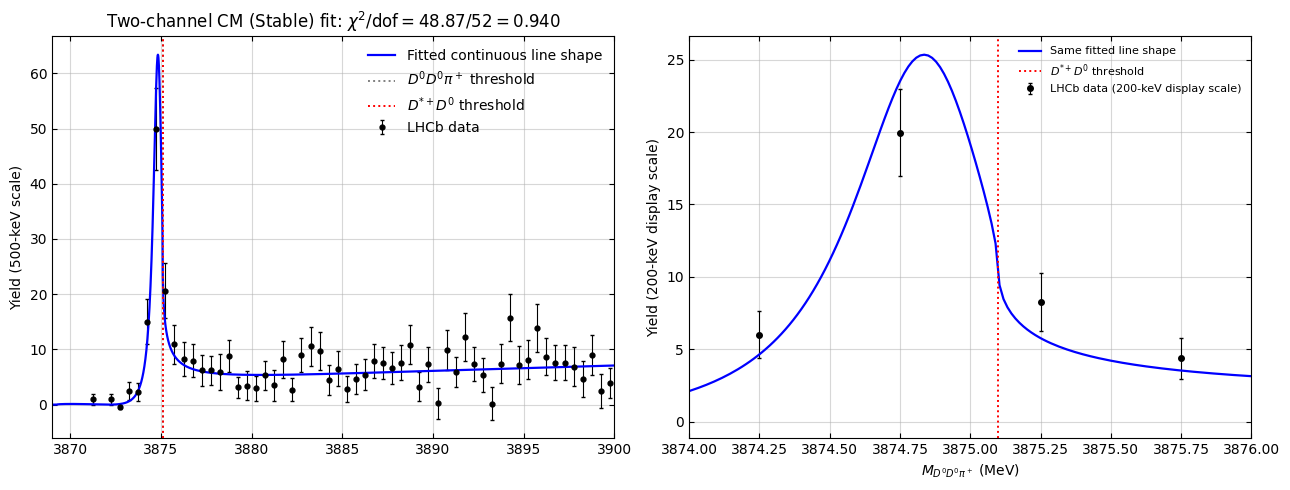

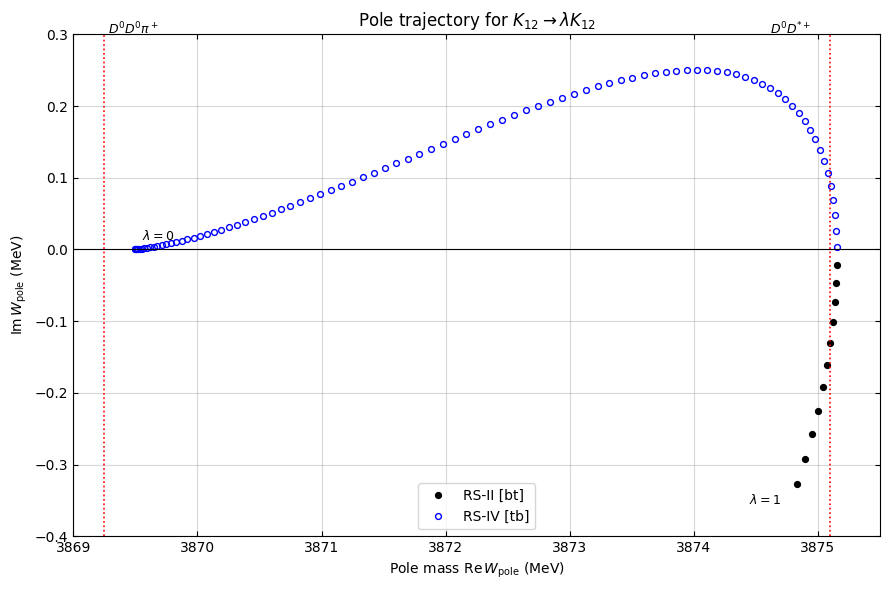

In [91]:
def make_fig1(
    W_centers,
    y_data,
    y_err,
    params,
    chi2,
    dof,
    output_path="Fig1_reproduced.png",
):
    K11, K12, K22, alpha2, log10_norm = params
    W_plot = np.linspace(3.8690, 3.9000, 2200)
    y_plot = line_shape(W_plot, *params)

    fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 5))

    ax_full.errorbar(
        W_centers * 1000.0,
        y_data,
        yerr=y_err,
        fmt="o",
        ms=3.5,
        color="black",
        ecolor="black",
        elinewidth=0.8,
        capsize=1.5,
        label="LHCb data",
    )
    ax_full.plot(
        W_plot * 1000.0,
        y_plot,
        color="blue",
        lw=1.6,
        label="Fitted continuous line shape",
    )
    ax_full.axvline(
        WTH2 * 1000.0,
        color="gray",
        ls=":",
        lw=1.4,
        label=r"$D^0D^0\pi^+$ threshold",
    )
    ax_full.axvline(
        WTH2 * 1000.0,
        color="red",
        ls=":",
        lw=1.4,
        label=r"$D^{*+}D^0$ threshold",
    )
    ax_full.set_xlim(3869.0, 3900.0)
    ax_full.set_ylabel("Yield (500-keV scale)")
    ax_full.set_title(
        rf"Two-channel CM (Stable) fit: $\chi^2/\mathrm{{dof}}={chi2:.2f}/{dof}={chi2/dof:.3f}$"
    )
    ax_full.legend(frameon=False, loc="upper right")
    ax_full.tick_params(direction="in", which="both", top=True, right=True)
    ax_full.grid(True, alpha=0.5)

    # Fig. 1's bottom panel displays yield per 200 keV instead of per 500 keV.
    # This is a display rescaling only; it is not used in the fit.
    zoom_scale = 200.0 / 500.0
    zoom_mask = (W_centers >= 3.8730) & (W_centers <= 3.8770)
    zoom_plot_mask = (W_plot >= 3.8730) & (W_plot <= 3.8770)
    ax_zoom.errorbar(
        W_centers[zoom_mask] * 1000.0,
        zoom_scale * y_data[zoom_mask],
        yerr=zoom_scale * y_err[zoom_mask],
        fmt="o",
        ms=4.0,
        color="black",
        ecolor="black",
        elinewidth=0.8,
        capsize=1.5,
        label="LHCb data (200-keV display scale)",
    )
    ax_zoom.plot(
        W_plot[zoom_plot_mask] * 1000.0,
        zoom_scale * y_plot[zoom_plot_mask],
        color="blue",
        lw=1.6,
        label="Same fitted line shape",
    )
    ax_zoom.axvline(
        WTH2 * 1000.0,
        color="red",
        ls=":",
        lw=1.4,
        label=r"$D^{*+}D^0$ threshold",
    )
    ax_zoom.set_xlim(3874.0, 3876.0)
    ax_zoom.set_xlabel(r"$M_{D^0D^0\pi^+}$ (MeV)")
    ax_zoom.set_ylabel("Yield (200-keV display scale)")
    ax_zoom.legend(frameon=False, loc="upper right", fontsize=8)
    ax_zoom.grid(True, alpha=0.5)
    ax_zoom.tick_params(direction="in", which="both", top=True, right=True)

    fig.tight_layout()
    return fig


def make_fig2(lambda_values, poles, sheets, output_path="Fig2_reproduced.png"):
    fig, ax = plt.subplots(figsize=(9, 6))
    sheets_array = np.asarray(sheets, dtype=object)
    for sheet, label, color, face in (
        ("bt", "RS-II [bt]", "black", "black"),
        ("tb", "RS-IV [tb]", "blue", "none"),
    ):
        mask = sheets_array == sheet
        if np.any(mask):
            ax.plot(
                poles.real[mask] * 1000.0,
                poles.imag[mask] * 1000.0,
                linestyle="none",
                marker="o",
                ms=4.2,
                markeredgecolor=color,
                markerfacecolor=face,
                label=label,
            )

    ax.axhline(0.0, color="black", lw=0.8)
    ax.axvline((M1 + m1) * 1000.0, color="red", ls=":", lw=1.2)
    ax.axvline((M2 + m2) * 1000.0, color="red", ls=":", lw=1.2)
    ax.text((M1 + m1) * 1000.0 + 0.03, 0.30, r"$D^0D^0\pi^+$", fontsize=9)
    ax.text((M2 + m2) * 1000.0 - 0.15, 0.30, r"$D^0D^{*+}$", fontsize=9, ha="right")

    i0 = int(np.argmin(np.abs(lambda_values - 0.0)))
    i1 = int(np.argmin(np.abs(lambda_values - 1.0)))
    ax.annotate(
        r"$\lambda=0$",
        (poles.real[i0] * 1000.0, poles.imag[i0] * 1000.0),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9,
    )
    ax.annotate(
        r"$\lambda=1$",
        (poles.real[i1] * 1000.0, poles.imag[i1] * 1000.0),
        xytext=(-35, -14),
        textcoords="offset points",
        fontsize=9,
    )

    ax.set_xlabel(r"Pole mass $\mathrm{Re}\,W_{\rm pole}$ (MeV)")
    ax.set_ylabel(r"$\mathrm{Im}\,W_{\rm pole}$ (MeV)")
    ax.set_title(r"Pole trajectory for $K_{12}\rightarrow\lambda K_{12}$")
    ax.set_xlim(3869.0, 3875.5)
    ax.set_ylim(-0.4, 0.3)
    ax.legend(frameon=True, loc="lower center")
    ax.grid(True, alpha=0.5)
    ax.tick_params(direction="in", which="both", top=True, right=True)
    fig.tight_layout()
    return fig


# =============================================================================
# 8. Main
# =============================================================================
def main():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Cannot find {DATA_PATH.resolve()}. Put Fig1.csv next to this script "
            "or edit DATA_PATH at the top."
        )

    (
        df_data,
        data_mass_MeV,
        data_mass_GeV,
        bin_low_GeV,
        bin_high_GeV,
        data_yield,
        data_err,
    ) = load_lhcb_data(DATA_PATH)
    W_quadrature, average_weights = make_bin_quadrature(bin_low_GeV, bin_high_GeV)

    print(f"Loaded {len(data_yield)} LHCb points from {DATA_PATH}")
    print(f"D0 D0 pi+ threshold: {WTH1 * 1000.0:.5f} MeV")
    print(f"D*+ D0 threshold:    {WTH2 * 1000.0:.5f} MeV")

    params, chi2, dof, bounds, de_result, ls_result = fit_without_manual_initial_guess(
        W_quadrature, average_weights, data_yield, data_err
    )
    K11, K12, K22, alpha2, log10_norm = params
    normalization = 10.0**log10_norm
    y_fit_bin_average = bin_averaged_line_shape(params, W_quadrature, average_weights)

    print("\n================ LEAST-SQUARES FIT ================")
    print(f"K11       = {K11:.10g}")
    print(f"K12       = {K12:.10g}")
    print(f"K22       = {K22:.10g}")
    print(f"alpha2    = {alpha2:.10g}")
    print(f"N         = {normalization:.10g}")
    print(f"chi2      = {chi2:.8g}")
    print(f"dof       = {dof}")
    print(f"chi2/dof  = {chi2 / dof:.8g}")
    print(f"Global-search chi2 = {de_result.fun:.8g}")

    fit_table = pd.DataFrame(
        {
            "parameter": [
                "K11",
                "K12",
                "K22",
                "alpha2",
                "N",
                "chi2",
                "dof",
                "chi2_dof",
            ],
            "value": [K11, K12, K22, alpha2, normalization, chi2, dof, chi2 / dof],
        }
    )
    fit_table.to_csv(
        r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\Tests\fit_results.csv", index=False
    )

    fig1 = make_fig1(
        data_mass_GeV,
        data_yield,
        data_err,
        params,
        chi2,
        dof,
        output_path="Fig1_reproduced.png",
    )

    pole, pole_candidates, count_by_sheet, pole_sheet = (
        find_physical_pole_by_delves_lyness(params)
    )

    print("\nAccepted pole candidates and momentum diagnostics:")
    for candidate in pole_candidates:
        z = candidate["W"]
        print(
            f"  search=[{candidate['search_sheet']}]  "
            f"identified=[{candidate['identified_sheet']}]  "
            f"W = {z.real * 1000.0:.6f} {z.imag * 1000.0:+.6f}i MeV, "
            f"Im(k1)={candidate['Im_k1']:+.8e}, "
            f"Im(k2)={candidate['Im_k2']:+.8e}, "
            f"|D|={candidate['residual']:.3e}"
        )

    print("\nComputing Fig. 2 pole trajectory for lambda=0...1...")
    lambda_values, trajectory_poles, trajectory_sheets = pole_trajectory(params)
    print("\nlambda    Re W_pole (MeV)    Im W_pole (MeV)    sheet")
    for lam, z, sheet in zip(lambda_values, trajectory_poles, trajectory_sheets):
        print(
            f"{lam:5.2f}    {z.real * 1000.0:14.6f}    {z.imag * 1000.0:14.6f}    [{sheet}]"
        )

    pd.DataFrame(
        {
            "lambda": lambda_values,
            "Re_W_pole_GeV": trajectory_poles.real,
            "Im_W_pole_GeV": trajectory_poles.imag,
            "Re_W_pole_MeV": trajectory_poles.real * 1000.0,
            "Im_W_pole_MeV": trajectory_poles.imag * 1000.0,
            "sheet": trajectory_sheets,
        }
    ).to_csv(
        r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\Tests\pole_trajectory.csv",
        index=False,
    )

    fig2 = make_fig2(
        lambda_values,
        trajectory_poles,
        trajectory_sheets,
        output_path="Fig2_reproduced.png",
    )
    plt.show(fig1)
    plt.show(fig2)
if __name__ == "__main__":
    main()